In [1]:
!pip -q install kagglehub transformers sentence-transformers faiss-cpu pypdf scikit-learn seaborn matplotlib

In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU available:", torch.cuda.is_available())
print("PROJECT SETUP COMPLETED")

Device: cuda
GPU available: True
PROJECT SETUP COMPLETED


In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

dataset_path = Path(dataset_path)

print("Dataset downloaded to:", dataset_path)

for item in dataset_path.iterdir():
    print(item.name)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded to: /kaggle/input/brain-tumor-mri-dataset
Training
Testing


In [4]:
train_dir = dataset_path / "Training"
test_dir = dataset_path / "Testing"

assert train_dir.exists(), f"Training folder not found: {train_dir}"
assert test_dir.exists(), f"Testing folder not found: {test_dir}"

class_names = sorted([
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
])

print("Classes:", class_names)

for class_name in class_names:
    count = len(list((train_dir / class_name).glob("*")))
    print(f"{class_name}: {count} training files")

print("DATASET CHECK COMPLETED")

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
glioma: 1400 training files
meningioma: 1400 training files
notumor: 1400 training files
pituitary: 1400 training files
DATASET CHECK COMPLETED


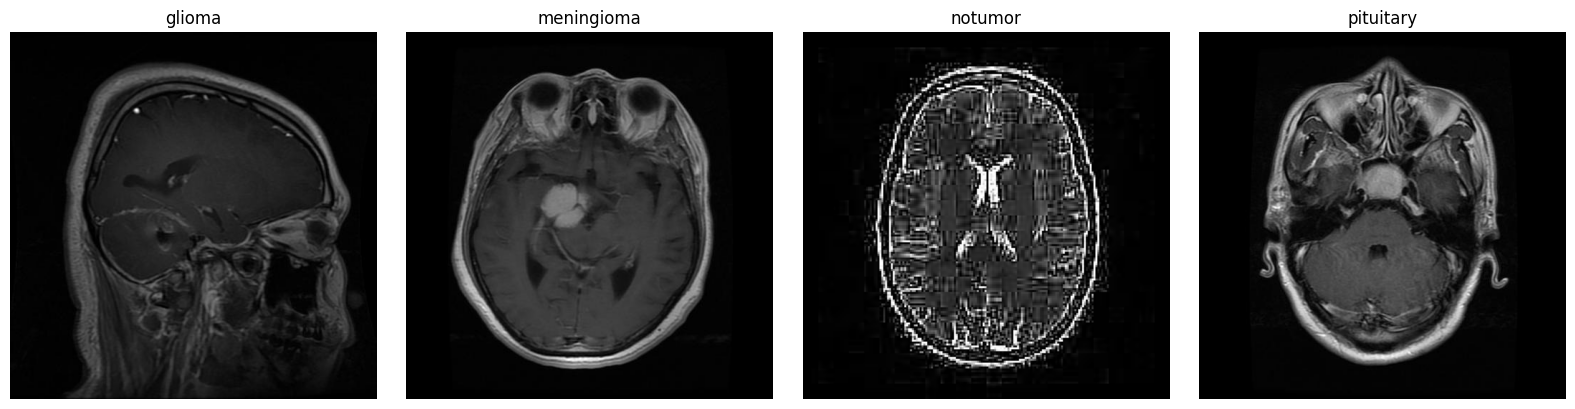

In [5]:
fig, axes = plt.subplots(
    1, len(class_names),
    figsize=(16, 4)
)

for i, class_name in enumerate(class_names):
    image_files = list((train_dir / class_name).glob("*"))

    if not image_files:
        continue

    image = Image.open(image_files[0]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [6]:
IMAGE_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(7),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing configured.")

Image preprocessing configured.


In [7]:
full_train_aug = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

full_train_eval = datasets.ImageFolder(
    train_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

assert full_train_aug.classes == full_train_eval.classes
assert full_train_aug.classes == test_dataset.classes

class_names = full_train_aug.classes

generator = torch.Generator().manual_seed(SEED)

train_size = int(0.85 * len(full_train_aug))
val_size = len(full_train_aug) - train_size

train_subset, val_subset = random_split(
    full_train_aug,
    [train_size, val_size],
    generator=generator
)

# Validation data must not use random training augmentation.
val_subset = torch.utils.data.Subset(
    full_train_eval,
    val_subset.indices
)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Classes:", class_names)
print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Testing images:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training images: 4760
Validation images: 840
Testing images: 1600


In [8]:
weights = models.ViT_B_16_Weights.IMAGENET1K_V1

model = models.vit_b_16(weights=weights)

# Replace the original classification head.
in_features = model.heads.head.in_features

model.heads.head = nn.Linear(
    in_features,
    len(class_names)
)

model = model.to(device)

# Freeze the pretrained transformer initially.
for param in model.parameters():
    param.requires_grad = False

for param in model.heads.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.heads.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Vision Transformer loaded successfully.")
print("Number of classes:", len(class_names))

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 81.0MB/s]


Vision Transformer loaded successfully.
Number of classes: 4


In [10]:
EPOCHS = 5
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0
best_model_path = "/content/best_brain_vit.pth"

def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names
        }, best_model_path)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

print("TRAINING COMPLETED")
print(f"Best validation accuracy: {best_val_acc:.2%}")

Epoch 1/5 | Train Loss: 0.4555 | Train Accuracy: 0.8395 | Val Loss: 0.3387 | Val Accuracy: 0.8750
Epoch 2/5 | Train Loss: 0.2664 | Train Accuracy: 0.9063 | Val Loss: 0.2925 | Val Accuracy: 0.8774
Epoch 3/5 | Train Loss: 0.2317 | Train Accuracy: 0.9181 | Val Loss: 0.2481 | Val Accuracy: 0.9012
Epoch 4/5 | Train Loss: 0.1973 | Train Accuracy: 0.9313 | Val Loss: 0.2232 | Val Accuracy: 0.9131
Epoch 5/5 | Train Loss: 0.1816 | Train Accuracy: 0.9372 | Val Loss: 0.2113 | Val Accuracy: 0.9143
TRAINING COMPLETED
Best validation accuracy: 91.43%


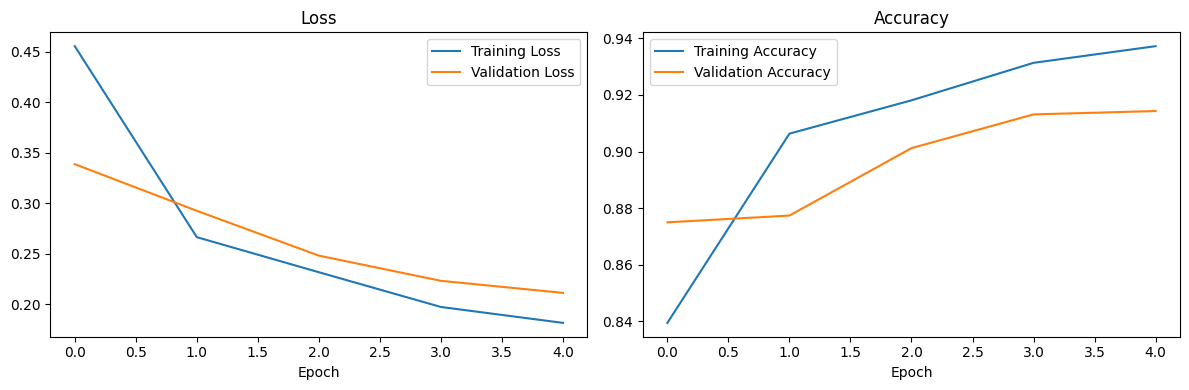

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Training Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("TEST EVALUATION COMPLETED")

Test Accuracy: 0.8819

Classification Report:

              precision    recall  f1-score   support

      glioma       0.98      0.69      0.80       400
  meningioma       0.76      0.91      0.83       400
     notumor       0.91      0.99      0.95       400
   pituitary       0.93      0.94      0.94       400

    accuracy                           0.88      1600
   macro avg       0.89      0.88      0.88      1600
weighted avg       0.89      0.88      0.88      1600

TEST EVALUATION COMPLETED


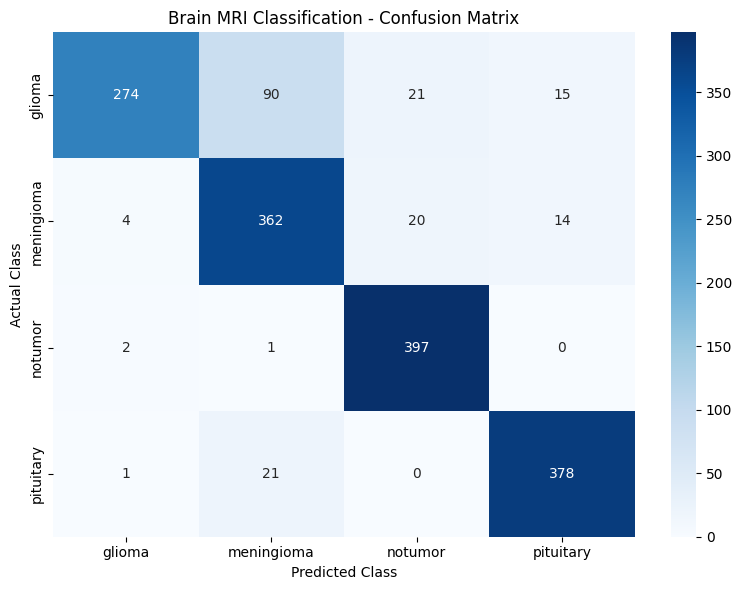

In [14]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Brain MRI Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

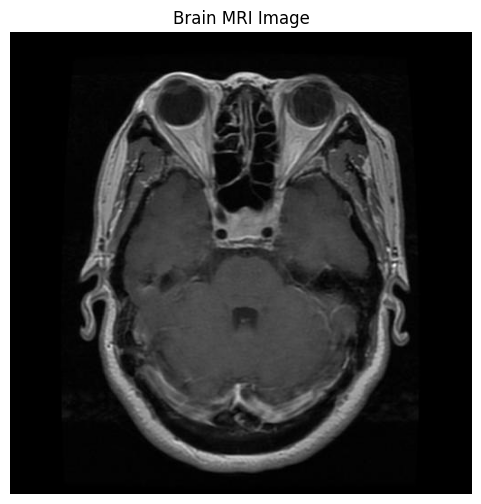

BRAIN TUMOR PREDICTION
Image: Te-pi_279.jpg
Actual Class: pituitary
Predicted Class: pituitary
Confidence: 94.34%
Educational use only - not a diagnosis.


In [16]:
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Get all MRI images from Testing folder
test_images = []

for class_name in class_names:
    folder = test_dir / class_name

    for file in folder.iterdir():
        if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            test_images.append(file)

assert len(test_images) > 0, "No test images found!"

# Automatically select image
image_path = random.choice(test_images)

image = Image.open(image_path).convert("RGB")

input_tensor = eval_transform(image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index].item()

actual_class = image_path.parent.name

# Display MRI
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Brain MRI Image")
plt.show()

print("=" * 45)
print("BRAIN TUMOR PREDICTION")
print("=" * 45)
print("Image:", image_path.name)
print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2%}")
print("Educational use only - not a diagnosis.")
print("=" * 45)

In [17]:
!pip -q install transformers sentence-transformers faiss-cpu

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sentence_transformers import SentenceTransformer
import faiss
import json
from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
documents = [
    {
        "text": """
        Brain tumors are abnormal growths of cells in or around the brain.
        They can be classified according to their origin, location and
        biological behavior.
        """,
        "source": "Brain Tumor Introduction"
    },
    {
        "text": """
        Glioma is a type of brain tumor that originates from glial cells.
        Gliomas have different grades and characteristics.
        """,
        "source": "Glioma Information"
    },
    {
        "text": """
        Meningiomas arise from the meninges, the membranes surrounding
        the brain and spinal cord. Many grow slowly.
        """,
        "source": "Meningioma Information"
    },
    {
        "text": """
        Pituitary tumors develop in or around the pituitary gland.
        They may affect hormone production.
        """,
        "source": "Pituitary Tumor Information"
    },
    {
        "text": """
        MRI stands for Magnetic Resonance Imaging. It uses magnetic
        fields and radio waves to create detailed images of internal
        structures and is commonly used to evaluate brain conditions.
        """,
        "source": "MRI Information"
    },
    {
        "text": """
        Possible symptoms of brain tumors include headaches, seizures,
        vision changes, weakness and balance difficulties. These
        symptoms can also have other causes.
        """,
        "source": "Brain Tumor Symptoms"
    },
    {
        "text": """
        Treatment depends on tumor type, grade, location and patient
        condition. Options may include surgery, radiation therapy
        and medicines. A specialist determines appropriate treatment.
        """,
        "source": "Treatment Information"
    },
    {
        "text": """
        AI models classify MRI images using patterns learned from
        training data. Their predictions are not confirmed diagnoses.
        """,
        "source": "AI Medical Limitations"
    }
]

print("Knowledge base created.")
print("Total documents:", len(documents))

Knowledge base created.
Total documents: 8


In [20]:
def chunk_text(text, chunk_size=100, overlap=20):

    words = text.split()
    chunks = []

    start = 0

    while start < len(words):

        end = min(start + chunk_size, len(words))

        chunks.append(" ".join(words[start:end]))

        if end == len(words):
            break

        start = end - overlap

    return chunks


chunks = []
chunk_sources = []

for document in documents:

    document_chunks = chunk_text(document["text"])

    for chunk in document_chunks:
        chunks.append(chunk)
        chunk_sources.append(document["source"])

print("Total chunks:", len(chunks))
print("Text chunking completed.")

Total chunks: 8
Text chunking completed.


In [21]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

embeddings = embedding_model.encode(
    chunks,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

print("Embedding shape:", embeddings.shape)
print("Embeddings generated successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding shape: (8, 384)
Embeddings generated successfully.


In [22]:
vector_dimension = embeddings.shape[1]

vector_index = faiss.IndexFlatIP(vector_dimension)

vector_index.add(embeddings)

print("FAISS database created.")
print("Total stored vectors:", vector_index.ntotal)

FAISS database created.
Total stored vectors: 8


In [23]:
LLM_NAME = "google/flan-t5-base"

tokenizer = AutoTokenizer.from_pretrained(
    LLM_NAME
)

llm = AutoModelForSeq2SeqLM.from_pretrained(
    LLM_NAME
)

llm = llm.to(device)
llm.eval()

print("LLM loaded successfully.")
print("Model:", LLM_NAME)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

LLM loaded successfully.
Model: google/flan-t5-base


In [24]:
def retrieve_context(question, top_k=3):

    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    top_k = min(top_k, len(chunks))

    scores, indices = vector_index.search(
        query_embedding,
        top_k
    )

    results = []

    for score, index in zip(scores[0], indices[0]):

        if index < 0:
            continue

        results.append({
            "text": chunks[index],
            "source": chunk_sources[index],
            "score": float(score)
        })

    return results


print("Retrieval function ready.")

Retrieval function ready.


In [25]:
def ask_brain_tumor_assistant(question):

    retrieved = retrieve_context(question)

    if not retrieved:
        return "No relevant information found.", []

    context = "\n\n".join([
        item["text"] for item in retrieved
    ])

    prompt = f"""
    You are an educational brain tumor assistant.

    Answer using only the supplied context.
    If information is missing, say so.
    Do not diagnose patients or prescribe treatments.

    Context:
    {context}

    Question:
    {question}

    Answer:
    """

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, retrieved


print("RAG assistant ready.")

RAG assistant ready.


In [29]:
question = "What is a brain tumor?"

answer, sources = ask_brain_tumor_assistant(question)

print("=" * 50)
print("BRAIN TUMOR AI ASSISTANT")
print("=" * 50)

print("\nQuestion:", question)

print("\nAnswer:")
print(answer)

print("\nSources:")

for source in sources:
    print("-", source["source"])

print("\nCHATBOT TEST COMPLETED")

BRAIN TUMOR AI ASSISTANT

Question: What is a brain tumor?

Answer:
abnormal growths of cells in or around the brain

Sources:
- Brain Tumor Introduction
- Glioma Information
- Brain Tumor Symptoms

CHATBOT TEST COMPLETED


In [31]:
print("BRAIN TUMOR EDUCATIONAL CHATBOT")
print("Type exit to stop.")

while True:

    question = input("\nYou: ").strip()

    if question.lower() in ["exit", "quit", "stop"]:
        print("Chatbot stopped.")
        break

    if not question:
        print("Please enter a question.")
        continue

    answer, sources = ask_brain_tumor_assistant(question)

    print("\nAssistant:", answer)

    print("\nSources:")

    for source in sources:
        print("-", source["source"])

    print("-" * 50)

BRAIN TUMOR EDUCATIONAL CHATBOT
Type exit to stop.

You: What are the most common warning signs?

Assistant: headaches, seizures, vision changes, weakness and balance difficulties

Sources:
- Brain Tumor Symptoms
- AI Medical Limitations
- Pituitary Tumor Information
--------------------------------------------------

You: How are they diagnosed?

Assistant: origin, location and biological behavior

Sources:
- Treatment Information
- Brain Tumor Symptoms
- Brain Tumor Introduction
--------------------------------------------------

You: What is the exact type, location, and grade of the tumor?

Assistant: origin, location and biological behavior

Sources:
- Treatment Information
- Brain Tumor Introduction
- Glioma Information
--------------------------------------------------

You: What do tumor "grades" mean?

Assistant: classification

Sources:
- Brain Tumor Introduction
- Glioma Information
- Treatment Information
--------------------------------------------------

You: exit
Chatbot

In [32]:
PROJECT_DIR = Path("/content/brain_tumor_ai_project")

PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save ViT model
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "test_accuracy": float(test_accuracy)
}, PROJECT_DIR / "brain_tumor_vit.pth")

# Save FAISS database
faiss.write_index(
    vector_index,
    str(PROJECT_DIR / "brain_tumor_faiss.index")
)

# Save RAG documents
with open(
    PROJECT_DIR / "rag_documents.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump({
        "chunks": chunks,
        "sources": chunk_sources
    }, file, indent=4, ensure_ascii=False)

# Save evaluation report
with open(
    PROJECT_DIR / "evaluation.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(f"Test Accuracy: {test_accuracy:.4f}\n")

    file.write(
        classification_report(
            all_labels,
            all_predictions,
            labels=list(range(len(class_names))),
            target_names=class_names,
            zero_division=0
        )
    )

print("PROJECT FILES SAVED SUCCESSFULLY")

for file in PROJECT_DIR.iterdir():
    print(file.name)

PROJECT FILES SAVED SUCCESSFULLY
brain_tumor_faiss.index
rag_documents.json
evaluation.txt
brain_tumor_vit.pth


In [33]:
import shutil

zip_path = shutil.make_archive(
    "/content/brain_tumor_ai_project",
    "zip",
    PROJECT_DIR
)

print("BRAIN TUMOR AI PROJECT COMPLETED")

from google.colab import files

files.download(zip_path)

BRAIN TUMOR AI PROJECT COMPLETED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
print("=" * 65)
print("       BRAIN TUMOR DETECTION & LLM ASSISTANT")
print("                  FINAL SUMMARY")
print("=" * 65)

print("\nPROJECT INFORMATION")
print("-" * 65)

print("Project Name       : Brain Tumor Detection & LLM Assistant")
print("Dataset            : Brain Tumor MRI Dataset (Kaggle)")
print("Classification     : Vision Transformer (ViT)")
print("Language Model     : Google FLAN-T5 Base")
print("RAG Framework      : Retrieval Augmented Generation")
print("Embedding Model    : all-MiniLM-L6-v2")
print("Vector Database    : FAISS")

print("\nDATASET INFORMATION")
print("-" * 65)

print("Total Training     :", len(train_subset))
print("Total Validation   :", len(val_subset))
print("Total Testing      :", len(test_dataset))
print("Total Classes      :", len(class_names))
print("Class Names        :", ", ".join(class_names))

print("\nMODEL PERFORMANCE")
print("-" * 65)

print(f"Test Accuracy      : {test_accuracy * 100:.2f}%")
print(f"Best Validation    : {best_val_acc * 100:.2f}%")

print("\nCLASSIFICATION METRICS")
print("-" * 65)

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\nCHATBOT INFORMATION")
print("-" * 65)

print("LLM Model          : google/flan-t5-base")
print("Knowledge Documents:", len(documents))
print("Text Chunks        :", len(chunks))
print("FAISS Vectors      :", vector_index.ntotal)
print("RAG System         : Completed")

print("\nOUTPUT FILES")
print("-" * 65)

print("1. brain_tumor_vit.pth")
print("2. brain_tumor_faiss.index")
print("3. rag_documents.json")
print("4. evaluation.txt")
print("5. brain_tumor_predictions.csv")

print("\nPROJECT STATUS")
print("-" * 65)

print("MRI Classification : COMPLETED")
print("LLM Integration    : COMPLETED")
print("RAG Implementation : COMPLETED")
print("Prediction CSV     : COMPLETED")

print("\n" + "=" * 65)
print("       BRAIN TUMOR AI PROJECT COMPLETED")
print("=" * 65)

print("\nNote: This is an educational research project.")
print("AI predictions are not a medical diagnosis.")

       BRAIN TUMOR DETECTION & LLM ASSISTANT
                  FINAL SUMMARY

PROJECT INFORMATION
-----------------------------------------------------------------
Project Name       : Brain Tumor Detection & LLM Assistant
Dataset            : Brain Tumor MRI Dataset (Kaggle)
Classification     : Vision Transformer (ViT)
Language Model     : Google FLAN-T5 Base
RAG Framework      : Retrieval Augmented Generation
Embedding Model    : all-MiniLM-L6-v2
Vector Database    : FAISS

DATASET INFORMATION
-----------------------------------------------------------------
Total Training     : 4760
Total Validation   : 840
Total Testing      : 1600
Total Classes      : 4
Class Names        : glioma, meningioma, notumor, pituitary

MODEL PERFORMANCE
-----------------------------------------------------------------
Test Accuracy      : 88.19%
Best Validation    : 91.43%

CLASSIFICATION METRICS
-----------------------------------------------------------------
              precision    recall  f1-sco